SANTIAGO DIE MOREJÓN - 22/03/2026 - IA - Entregable 1 - Adicional 1 - Optimización y Búsqueda de Hiperparámetros

# Notebook 4 - Adicional 1: Optimización de Descriptores y Búsqueda de Hiperparámetros

En el notebook de comparativa concluimos que Random Forest con 5 descriptores fue el mejor modelo base con un accuracy de 0.747. Sin embargo, los modelos se evaluaron con parámetros por defecto y sin optimizar los hiperparámetros ni los descriptores.

En este notebook adicional vamos a intentar superar esa marca mediante dos estrategias:

1. Optimizacion de descriptores creando nuevos descriptores, combinando los descriptores más discriminativos.
2. Búsqueda de hiperparámetros para encontrar la configuración óptima de cada modelo no lineal.

## 1. Carga de datos y librerías

Cargamos los datos desde el repositorio y preparamos todas las herramientas necesarias.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
%config InlineBackend.figure_format = 'svg'

In [ ]:
!wget -q DATA_URL -O train.csv
!wget -q DATA_URL  -O test.csv

In [ ]:
traindf = pd.read_csv('train.csv')
testdf  = pd.read_csv('test.csv')

## 2. Optimización de Descriptores

Vamos a probar los modelos no lineales con dos configuraciones. En ambas se realizo la transformacion logaritmica a los descriptores `SL` y `CIRCULATION`. En el primero se dejan los 5 descriptores originales, ya que concluimos que daba mejores resultados que eliminando alguno y en la segunda configuracion usaremos nuevos descriptores.

In [ ]:
traindf['SL'] = np.log1p(traindf['SL'])
traindf['CIRCULATION'] = np.log1p(traindf['CIRCULATION'])

In [ ]:
testdf['SL'] = np.log1p(testdf['SL'])
testdf['CIRCULATION'] = np.log1p(testdf['CIRCULATION'])

 Creamos a partir de los descriptores `HR` y `BP` que son los dos  más discriminativos los siguientes descriptores:
  * `HR_BP_ratio`:  HR/BP
  * `HR_BP_product`:  HR×BP
  * `HR_BP_diff`:  HR−BP

In [ ]:
traindf_opti= traindf.copy()
traindf_opti['HR_BP_ratio'] = traindf_opti['HR'] / (traindf_opti['BP'] + 1e-6)
traindf_opti['HR_BP_product'] = traindf_opti['HR'] * traindf_opti['BP']
traindf_opti['HR_BP_diff'] = traindf_opti['HR'] - traindf_opti['BP']

In [ ]:
testdf_opti= testdf.copy()
testdf_opti['HR_BP_ratio'] = testdf_opti['HR'] / (testdf_opti['BP'] + 1e-6)
testdf_opti['HR_BP_product'] = testdf_opti['HR'] * testdf_opti['BP']
testdf_opti['HR_BP_diff'] = testdf_opti['HR'] - testdf_opti['BP']

### 2.1 Separación de datos y escalado

Hacemos dos splits independientes y en ambos casos usamos
`test_size=0.25` y `random_state=42` para que los resultados sean comparables con los del Notebook 3 y entre ellos.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
cols = ['SL', 'EEG', 'BP', 'HR', 'CIRCULATION']
cols_opti = ['SL', 'EEG', 'BP', 'HR', 'CIRCULATION', 'HR_BP_ratio', 'HR_BP_product', 'HR_BP_diff']

Split del Dataset con 5 descriptores

In [ ]:
X = traindf[cols].values
y = traindf['ACTIVITY'].values

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

Split del Dataset ampliado

In [ ]:
X_opti = traindf_opti[cols_opti].values
y_opti = traindf_opti['ACTIVITY'].values

X_train_opti, X_test_opti, y_train_opti, y_test_opti = train_test_split( X_opti, y_opti, test_size=0.25, random_state=42, stratify=y_opti)

scaler_opti = StandardScaler()
X_train_sc_opti = scaler_opti.fit_transform(X_train_opti)
X_test_sc_opti  = scaler_opti.transform(X_test_opti)

## 3. Función de evaluación

Definimos una función `evalua` que recibe un modelo ya entrenado y devuelve su accuracy sobre el conjunto de test.

In [ ]:
from sklearn.metrics import accuracy_score

def evalua(model, X_test, y_test):
    predicciones = model.predict(X_test)
    return accuracy_score(y_test, predicciones)

## 4. Búsqueda de Hiperparámetros con RandomizedSearchCV

Usare `RandomizedSearchCV` en lugar de `GridSearchCV` para hacer la busqueda de hiperparámetros mas eficientemente.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import cross_val_score
from scipy.stats import randint
from scipy.stats import uniform

### 4.1 Random Forest

Random Forest fue el mejor modelo base . Buscamos optimizar el número de árboles, la profundidad máxima y el tamaño mínimo para dividir un nodo.

* Modelo Random Forest por defecto para el Dataset con 5 descriptores

In [ ]:
rf_base = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)

* Modelo Random Forest optimizado para el Dataset con 5 descriptores

In [ ]:
rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    {'n_estimators': randint(100,600),
     'max_depth': [None,10,20,30,50],
     'min_samples_split': randint(2,20)},
    n_iter=50, scoring='accuracy', cv=5, random_state=42, n_jobs=-1
).fit(X_train, y_train)

In [ ]:
print(f'RF Base:{evalua(rf_base, X_test, y_test):.4f}')
print(f'RF Optimizado: {evalua(rf_search.best_estimator_, X_test, y_test):.4f}')
print(f'Mejores parametros {rf_search.best_params_}')

RF Base:0.7467
RF Optimizado: 0.7510
Mejores parametros {'max_depth': 30, 'min_samples_split': 5, 'n_estimators': 321}


* Modelo Random Forest por defecto para el Dataset ampliado

In [ ]:
rf_base_opti = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train_opti, y_train_opti)

* Modelo Random Forest optimizado para el Dataset ampliado

In [ ]:
rf_search_opti = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    {'n_estimators': randint(100,600),
     'max_depth': [None,10,20,30,50],
     'min_samples_split': randint(2,20)},
    n_iter=50, scoring='accuracy', cv=5, random_state=42, n_jobs=-1
).fit(X_train_opti, y_train_opti)

In [ ]:
print(f'RF Base opti: {evalua(rf_base_opti, X_test_opti, y_test_opti):.4f}')
print(f'RF Optimizado opti: {evalua(rf_search_opti.best_estimator_, X_test_opti, y_test_opti):.4f}')
print(f'Mejores parametros {rf_search_opti.best_params_}')

RF Base opti: 0.7347
RF Optimizado opti: 0.7347
Mejores parametros {'max_depth': 50, 'min_samples_split': 4, 'n_estimators': 271}


### 4.2 Árbol de Decisión

El árbol de decisión obtuvo 0.677 en la comparativa del notebook 3. Exploramos profundidad, criterio de impureza y tamaño mínimo de hoja.

* Modelo Árbol de Decisión por defecto para el Dataset con 5 descriptores

In [ ]:
dt_base = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

* Modelo Árbol de Decisión optimizado para el Dataset con 5 descriptores

In [ ]:
dt_search = RandomizedSearchCV(
    DecisionTreeClassifier(random_state=42),
    {'max_depth': [None,5,10,15,20,30],
     'criterion': ['gini','entropy'],
     'min_samples_split': randint(2,20)},
    n_iter=50, scoring='accuracy', cv=5, random_state=42, n_jobs=-1
).fit(X_train, y_train)

In [ ]:
print(f'DT Base: {evalua(dt_base, X_test, y_test):.4f}')
print(f'DT Optimizado: {evalua(dt_search.best_estimator_, X_test, y_test):.4f}')
print(f'Mejores parametros {dt_search.best_params_}')

DT Base: 0.6800
DT Optimizado: 0.6747
Mejores parametros {'criterion': 'entropy', 'max_depth': 15, 'min_samples_split': 9}


* Modelo Árbol de Decisión por defecto para el Dataset ampliado

In [ ]:
dt_base_opti = DecisionTreeClassifier(random_state=42).fit(X_train_opti, y_train_opti)

* Modelo Árbol de Decisión optimizado para el Dataset ampliado

In [ ]:
dt_search_opti = RandomizedSearchCV(
    DecisionTreeClassifier(random_state=42),
    {'max_depth': [None,5,10,15,20,30],
     'criterion': ['gini','entropy'],
     'min_samples_split': randint(2,20)},
    n_iter=50, scoring='accuracy', cv=5, random_state=42, n_jobs=-1
).fit(X_train_opti, y_train_opti)

In [ ]:
print(f'DT Base opti:       {evalua(dt_base_opti, X_test_opti, y_test_opti):.4f}')
print(f'DT Optimizado opti: {evalua(dt_search_opti.best_estimator_, X_test_opti, y_test_opti):.4f}')
print(f'Mejores parametros {dt_search_opti.best_params_}')

DT Base opti:       0.6693
DT Optimizado opti: 0.6813
Mejores parametros {'criterion': 'gini', 'max_depth': 15, 'min_samples_split': 5}


### 4.3 KNN

KNN obtuvo 0.645 con k=5.

* Modelo KNN por defecto para el Dataset con 5 descriptores

In [ ]:
knn_base = KNeighborsClassifier(n_neighbors=5).fit(X_train_sc, y_train)

* Modelo KNN optimizado para el Dataset con 5 descriptores

In [ ]:
knn_search = RandomizedSearchCV(
    KNeighborsClassifier(),
    {'n_neighbors': list(range(3,25,2)),
     'weights': ['uniform','distance'],
     'p': [1,2]},
    n_iter=50, scoring='accuracy', cv=5, random_state=42, n_jobs=-1
).fit(X_train_sc, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 44 is smaller than n_iter=50. Running 44 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


In [ ]:
print(f'KNN Base: {evalua(knn_base, X_test_sc, y_test):.4f}')
print(f'KNN Optimizado: {evalua(knn_search.best_estimator_, X_test_sc, y_test):.4f}')
print(f'Mejores parametros {knn_search.best_params_}')

KNN Base: 0.6360
KNN Optimizado: 0.6377
Mejores parametros {'weights': 'uniform', 'p': 1, 'n_neighbors': 3}


* Modelo KNN por defecto para el Dataset ampliado

In [ ]:
knn_base_opti = KNeighborsClassifier(n_neighbors=5).fit(X_train_sc_opti, y_train_opti)

* Modelo KNN optimizado para el Dataset ampliado

In [ ]:
knn_search_opti = RandomizedSearchCV(
    KNeighborsClassifier(),
    {'n_neighbors': list(range(3,25,2)),
     'weights': ['uniform','distance'],
     'p': [1,2]},
    n_iter=50, scoring='accuracy', cv=5, random_state=42, n_jobs=-1
).fit(X_train_sc_opti, y_train_opti)

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 44 is smaller than n_iter=50. Running 44 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


In [ ]:
print(f'KNN Base opti: {evalua(knn_base_opti, X_test_sc_opti, y_test_opti):.4f}')
print(f'KNN Optimizado opti: {evalua(knn_search_opti.best_estimator_, X_test_sc_opti, y_test_opti):.4f}')
print(f'Mejores parametros {knn_search_opti.best_params_}')

KNN Base opti: 0.6357
KNN Optimizado opti: 0.6403
Mejores parametros {'weights': 'distance', 'p': 2, 'n_neighbors': 3}


### 4.4 MLP

El MLP obtuvo 0.627 con una arquitectura fija de (100,100). Exploramos distintas arquitecturas, tasas de aprendizaje y regularización. MLP necesita datos escalados.

* Modelo MLP por defecto para el Dataset con 5 descriptores

In [ ]:
mlp_base = MLPClassifier(hidden_layer_sizes=(100,100), max_iter=500, random_state=42).fit(X_train_sc, y_train)

* Modelo MLP optimizado para el Dataset con 5 descriptores

In [ ]:
mlp_search = RandomizedSearchCV(
    MLPClassifier(max_iter=1000, random_state=42),
    {'hidden_layer_sizes': [(300,300),(500,300),(256,128),(300,200,100)],
     'alpha': uniform(1e-5, 1e-2),
     'learning_rate_init': uniform(1e-3, 1e-2),
     'activation': ['relu','tanh']},
    n_iter=20, scoring='accuracy', cv=5, random_state=42, n_jobs=-1
).fit(X_train_sc, y_train)

In [ ]:
print(f'MLP Base: {evalua(mlp_base, X_test_sc, y_test):.4f}')
print(f'MLP Optimizado: {evalua(mlp_search.best_estimator_, X_test_sc, y_test):.4f}')
print(f'Mejores parametros {mlp_search.best_params_}')

MLP Base: 0.6053
MLP Optimizado: 0.6530
Mejores parametros {'activation': 'relu', 'alpha': np.float64(0.005218342600258236), 'hidden_layer_sizes': (500, 300), 'learning_rate_init': np.float64(0.004253303307632643)}


* Modelo MLP por defecto para el Dataset ampliado

In [ ]:
mlp_base_opti = MLPClassifier(hidden_layer_sizes=(100,100), max_iter=500, random_state=42).fit(X_train_sc_opti, y_train_opti)

* Modelo MLP optimizado para el Dataset ampliado

In [ ]:
mlp_search_opti = RandomizedSearchCV(
    MLPClassifier(max_iter=1000, random_state=42),
    {'hidden_layer_sizes': [(300,300),(500,300),(256,128),(300,200,100)],
     'alpha': uniform(1e-5, 1e-2),
     'learning_rate_init': uniform(1e-3, 1e-2),
     'activation': ['relu','tanh']},
    n_iter=20, scoring='accuracy', cv=5, random_state=42, n_jobs=-1
).fit(X_train_sc_opti, y_train_opti)

In [ ]:
print(f'MLP Base opti:       {evalua(mlp_base_opti, X_test_sc_opti, y_test_opti):.4f}')
print(f'MLP Optimizado opti: {evalua(mlp_search_opti.best_estimator_, X_test_sc_opti, y_test_opti):.4f}')
print(f'Mejores parametros {mlp_search_opti.best_params_}')

MLP Base opti:       0.6173
MLP Optimizado opti: 0.6877
Mejores parametros {'activation': 'tanh', 'alpha': np.float64(0.0004766566321361543), 'hidden_layer_sizes': (300, 200, 100), 'learning_rate_init': np.float64(0.004663618432936917)}


## 5. Evaluación y Comparativa de Modelos Optimizados

Evaluamos cada modelo con sus mejores hiperparámetros sobre el conjunto de test (holdout 25%) y comparamos con los resultados base del Notebook 3.

In [ ]:
resultados = {
    'Random Forest': {
        'Base': evalua(rf_base, X_test, y_test),
        'Optimizado': evalua(rf_search.best_estimator_, X_test, y_test),
        'Base ampliado': evalua(rf_base_opti, X_test_opti, y_test_opti),
        'Optimizado ampliado': evalua(rf_search_opti.best_estimator_, X_test_opti, y_test_opti),
    },
    'Árbol Decisión': {
        'Base': evalua(dt_base, X_test, y_test),
        'Optimizado': evalua(dt_search.best_estimator_, X_test, y_test),
        'Base ampliado': evalua(dt_base_opti, X_test_opti, y_test_opti),
        'Optimizado ampliado': evalua(dt_search_opti.best_estimator_, X_test_opti, y_test_opti),
    },
    'KNN': {
        'Base': evalua(knn_base, X_test_sc, y_test),
        'Optimizado': evalua(knn_search.best_estimator_, X_test_sc, y_test),
        'Base ampliado': evalua(knn_base_opti, X_test_sc_opti, y_test_opti),
        'Optimizado ampliado': evalua(knn_search_opti.best_estimator_, X_test_sc_opti, y_test_opti),
    },
    'MLP': {
        'Base': evalua(mlp_base, X_test_sc, y_test),
        'Optimizado': evalua(mlp_search.best_estimator_, X_test_sc, y_test),
        'Base ampliado': evalua(mlp_base_opti, X_test_sc_opti, y_test_opti),
        'Optimizado ampliado': evalua(mlp_search_opti.best_estimator_, X_test_sc_opti, y_test_opti),
    },
}

In [ ]:
resultadosdf = pd.DataFrame(resultados).T.round(4).sort_values('Optimizado', ascending=False)
print(resultadosdf.to_string())

                  Base  Optimizado  Base ampliado  Optimizado ampliado
Random Forest   0.7467      0.7510         0.7347               0.7347
Árbol Decisión  0.6800      0.6747         0.6693               0.6813
MLP             0.6053      0.6530         0.6173               0.6877
KNN             0.6360      0.6377         0.6357               0.6403


### 5.1  Visualización de resultados

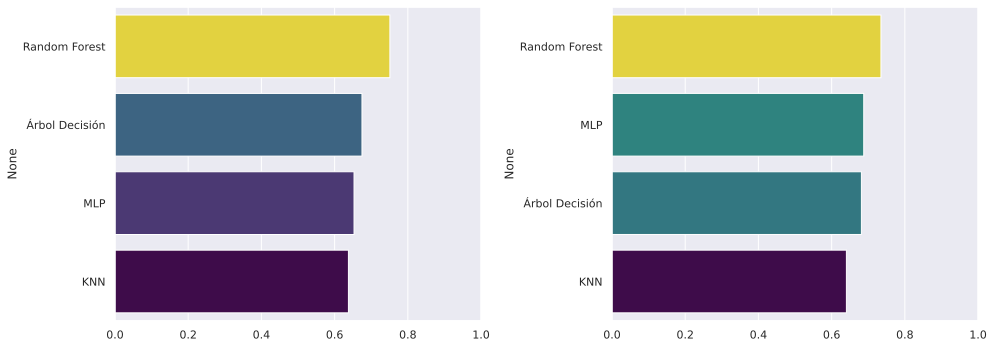

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

res_normal = resultadosdf['Optimizado'].sort_values(ascending=False)
sns.barplot(x=res_normal.values, hue=res_normal.values, y=res_normal.index, ax=axes[0], palette='viridis', legend=False)
axes[0].set_xlim(0, 1)

res_opti = resultadosdf['Optimizado ampliado'].sort_values(ascending=False)
sns.barplot(x=res_opti.values, hue=res_opti.values, y=res_opti.index, ax=axes[1], palette='viridis', legend=False)
axes[1].set_xlim(0, 1)

plt.tight_layout()

### 5.2 Analisis de los resultados

- Random Forest sigue siendo el modelo más preciso, pero es el que menos se beneficia en este notebook. Esto nos dice que los hiperparámetros por defecto ya son bastante buenos y los nuevos descriptores no le aportan mejoras.

- MLP es el modelo que más mejora con la búsqueda de hiperparámetros , lo que indica que la arquitectura por defecto (100,100) no era la mejor para el dataset.

- Árbol de Decisión es el único modelo donde la optimización de hiperparámetros empeora ligeramente el resultado en el dataset original , posiblemente por sobreajuste durante la búsqueda. Sin embargo, los nuevos descriptores sí le ayudan, aunque es muy poco.

- KNN mejora de muy poco en todas las configuraciones, lo que nos dice que su limitación es por su forma de clasificar.

Se confirma que Random Forest es el mejor modelo y hemos podido mejor los hiperparametros para una mejor prediccion.

## 6. Conclusión

En este notebook hemos aplicado dos estrategias para intentar aumentar el accuracy base de 0.751 obtenido por Random Forest en el notebook de comparativa.

Por un lado, buscamos hiperparámetros con `RandomizedSearchCV` (50 iteraciones, 5-fold CV) que permitio mejorar el rendimiento de todos los modelos.

Por otro lado, la creación de nuevos descriptores a partir de HR y BP (`HR_BP_ratio`, `HR_BP_product`, `HR_BP_diff`) ha aportado mejoras ligeras en la mayoría de los modelos.

Sin embargo, estas conclusiones se basan en un único split. En el siguiente notebook (Adicional 2) aplicaremos la metodología estadística vista en la Práctica 6 para confirmar si las diferencias entre modelos son estadísticamente significativas.